# **Lab 9 - Morphological Operations**
### Name: Abdullah Alnaji
### ID: 2240007157

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Erosion.jpg'

# **Erosion Operations**

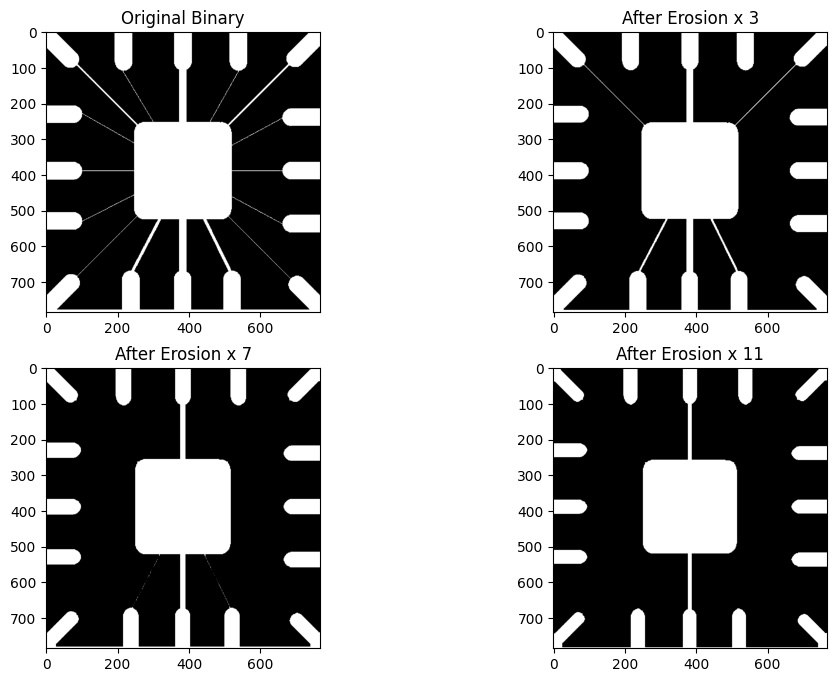

In [4]:

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)
eroded_img11 = cv2.erode(binary, kernel11, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Erosion x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Erosion x 7')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Erosion x 11')


plt.show()


# **Dilation Operations**

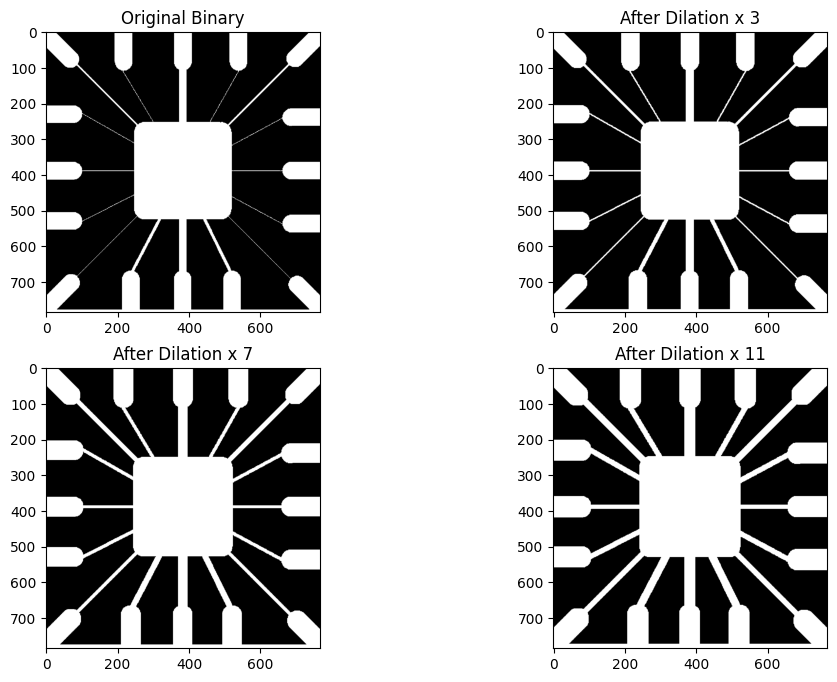

In [5]:

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.dilate(binary, kernel3, iterations=1)
eroded_img7 = cv2.dilate(binary, kernel7, iterations=1)
eroded_img11 = cv2.dilate(binary, kernel11, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Dilation x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Dilation x 7')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Dilation x 11')


plt.show()


# **Morphological Open Operations**

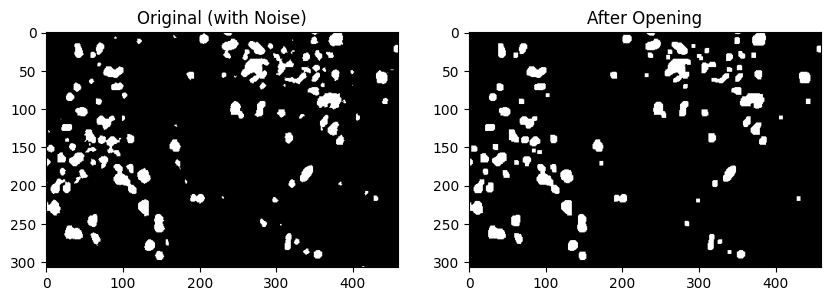

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Open_Closing.jpg'

# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 5x5 square is a good starting point)
kernel = np.ones((5, 5), np.uint8)

# 3. Apply Opening
# This is equivalent to: dilate(erode(binary))
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original (with Noise)')
plt.subplot(1, 2, 2), plt.imshow(opening, 'gray'), plt.title('After Opening')
plt.show()


# **Closing Morphological Operation**

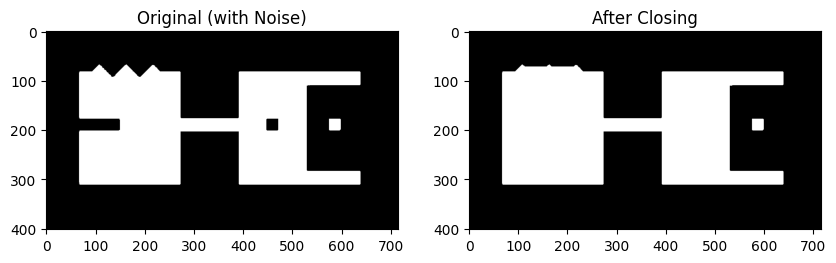

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Opening2.jpg'

# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 45x45 square is a good starting point)
kernel = np.ones((45, 45), np.uint8)

# 3. Apply Opening
# Effectively: cv2.erode(cv2.dilate(binary, kernel), kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original (with Noise)')
plt.subplot(1, 2, 2), plt.imshow(closing, 'gray'), plt.title('After Closing')
plt.show()


# **Boundaries Extractions**

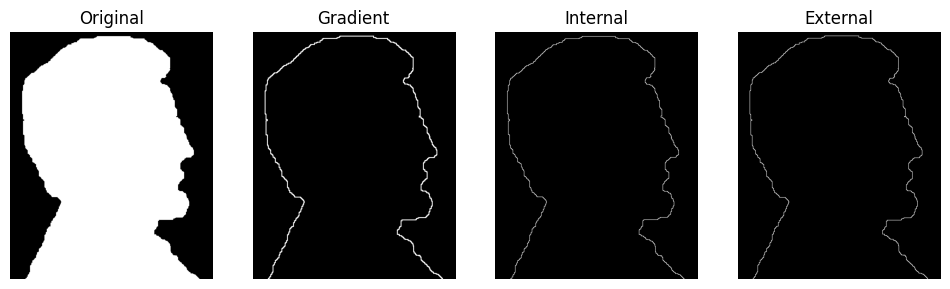

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


imgFile = 'BoundaryExtraction.jpg'
# 1. Load and binarize the image (foreground must be white)
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define a kernel (the size controls boundary thickness)
kernel = np.ones((3, 3), np.uint8)

# 3. Method A: Morphological Gradient (Built-in standard)
gradient = cv2.morphologyEx(binary, cv2.MORPH_GRADIENT, kernel)

# 4. Method B: Internal Boundary (Original - Eroded)
eroded = cv2.erode(binary, kernel)
internal = cv2.subtract(binary, eroded)

# 5. Method C: External Boundary (Dilated - Original)
dilated = cv2.dilate(binary, kernel)
external = cv2.subtract(dilated, binary)

# Visualization
titles = ['Original', 'Gradient', 'Internal', 'External']
images = [binary, gradient, internal, external]

plt.figure(figsize=(12, 4))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.show()

# **Lab 9 Tasks**


# **Task 1: Apply Morphological Operations to a New Image (Balls)**


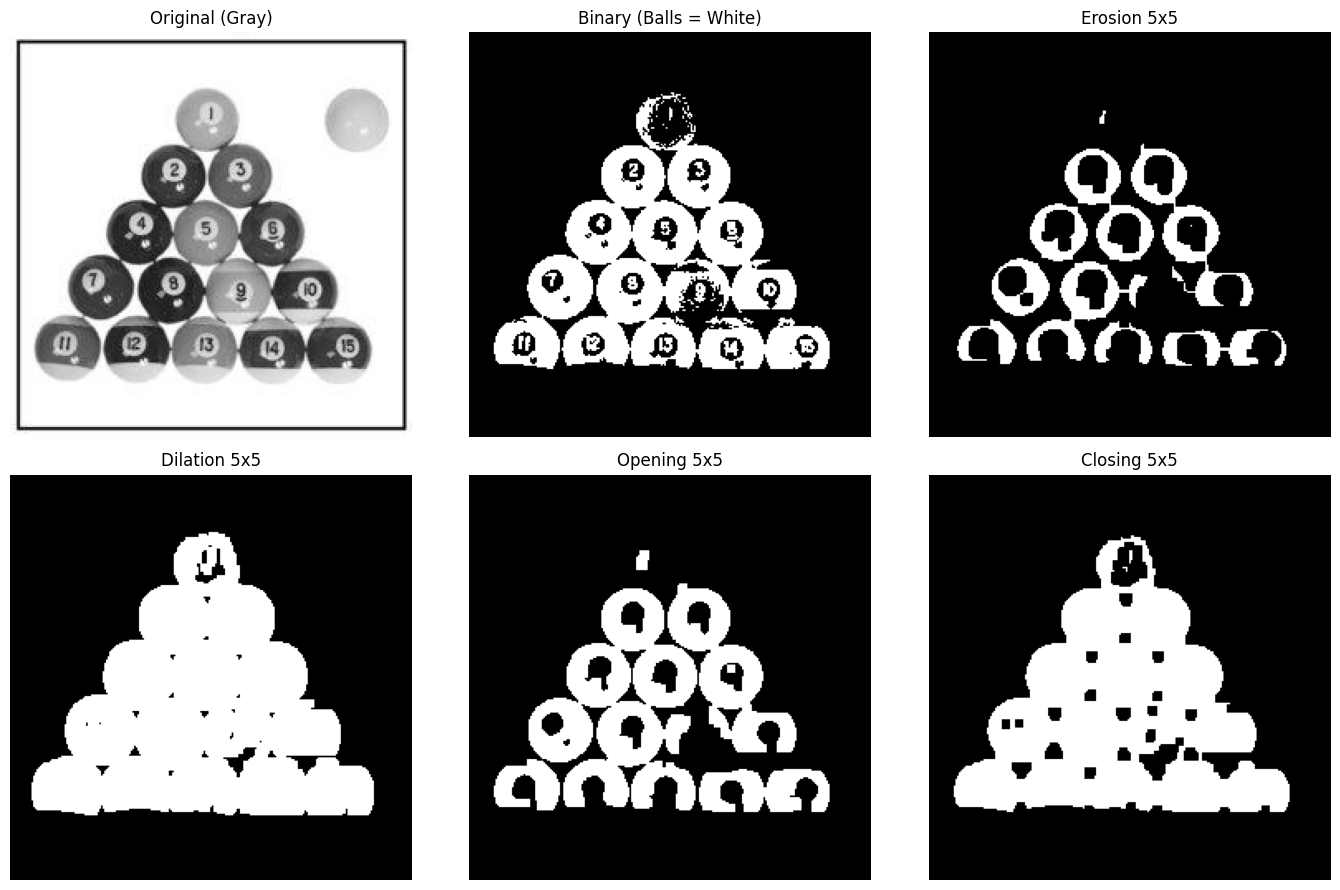

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Balls.png'

# 1. Load image in grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize with Otsu's method.
# THRESH_BINARY_INV is used so the balls become WHITE (foreground = 255)
# and the light background becomes BLACK (0), as morphology expects.
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 3. Remove the thin black frame around the picture (it would be detected as foreground)
binary[:8, :] = 0
binary[-8:, :] = 0
binary[:, :8] = 0
binary[:, -8:] = 0

# 4. Kernel (5x5 square)
kernel = np.ones((5, 5), np.uint8)

# 5. Apply the four operations
eroded  = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 6. Display original + results
titles = ['Original (Gray)', 'Binary (Balls = White)', 'Erosion 5x5',
          'Dilation 5x5', 'Opening 5x5', 'Closing 5x5']
images = [img, binary, eroded, dilated, opening, closing]

plt.figure(figsize=(14, 9))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()


# **Task 2: Experiment with Structuring Elements**


In [16]:
# Structuring element shapes: square, cross, ellipse
shapes = {
    'Square':  cv2.MORPH_RECT,
    'Cross':   cv2.MORPH_CROSS,
    'Ellipse': cv2.MORPH_ELLIPSE
}
sizes = [3, 5, 7]

def show_grid(operation, op_name):
    """Rows = shapes, Columns = kernel sizes"""
    plt.figure(figsize=(12, 12))
    k = 1
    for shape_name, shape in shapes.items():
        for s in sizes:
            kernel = cv2.getStructuringElement(shape, (s, s))
            result = operation(binary, kernel, iterations=1)
            plt.subplot(3, 3, k)
            plt.imshow(result, 'gray')
            plt.title(f'{op_name} - {shape_name} {s}x{s}')
            plt.axis('off')
            k += 1
    plt.tight_layout()
    plt.show()


## Structuring elements used


In [12]:
# Print the kernels to see how the shapes differ (7x7 example)
for shape_name, shape in shapes.items():
    print(shape_name, '7x7:')
    print(cv2.getStructuringElement(shape, (7, 7)))
    print()


Square 7x7:
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]

Cross 7x7:
[[0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [1 1 1 1 1 1 1]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]]

Ellipse 7x7:
[[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]



## Erosion with different shapes and sizes


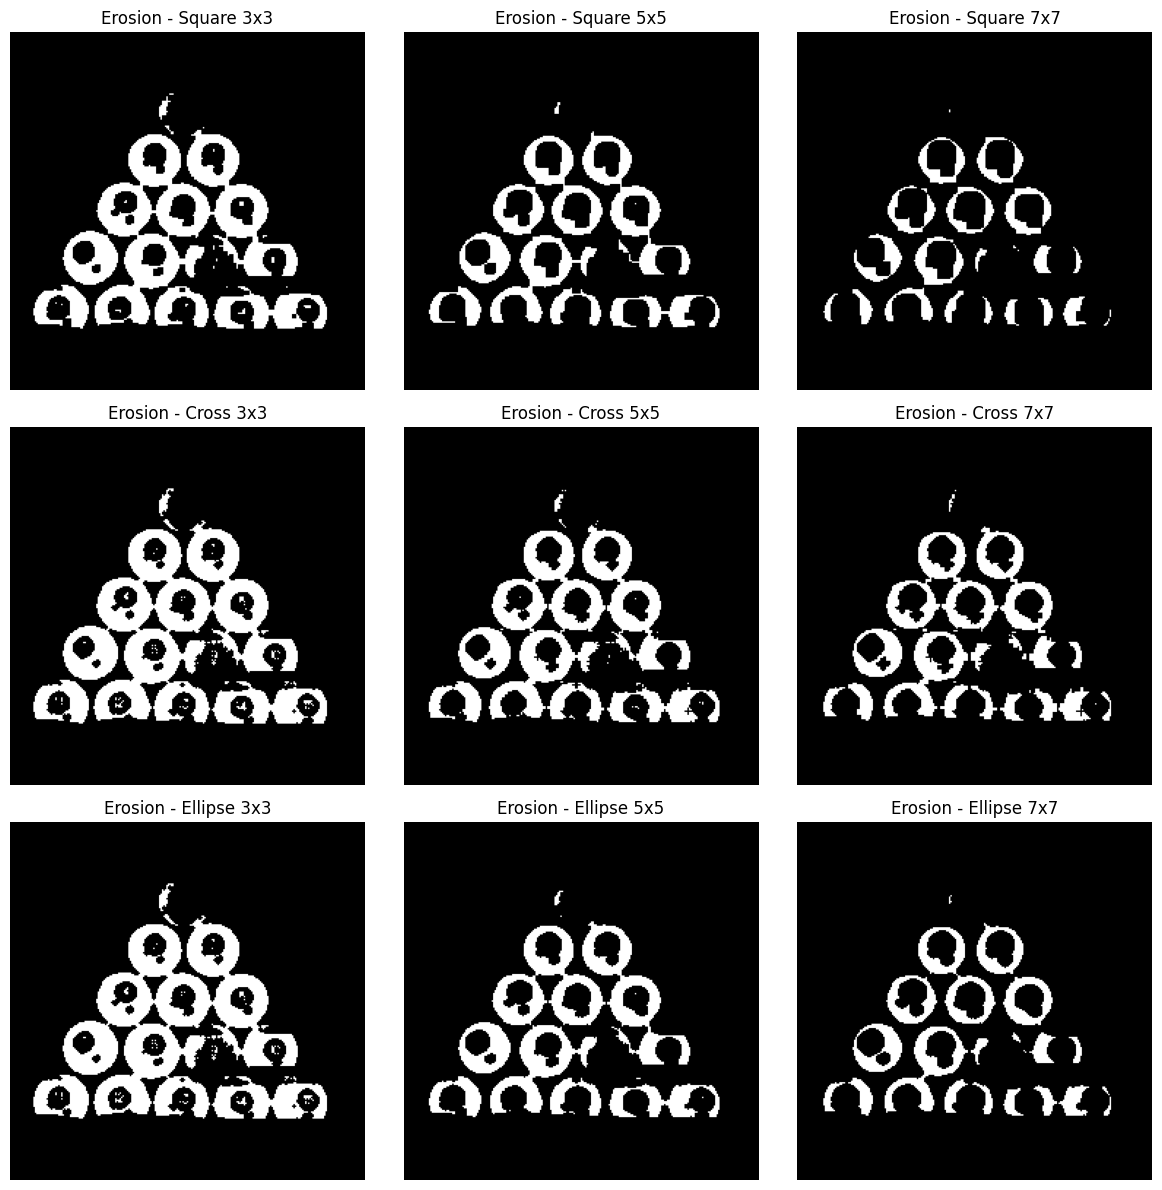

In [13]:
show_grid(cv2.erode, 'Erosion')


## Dilation with different shapes and sizes


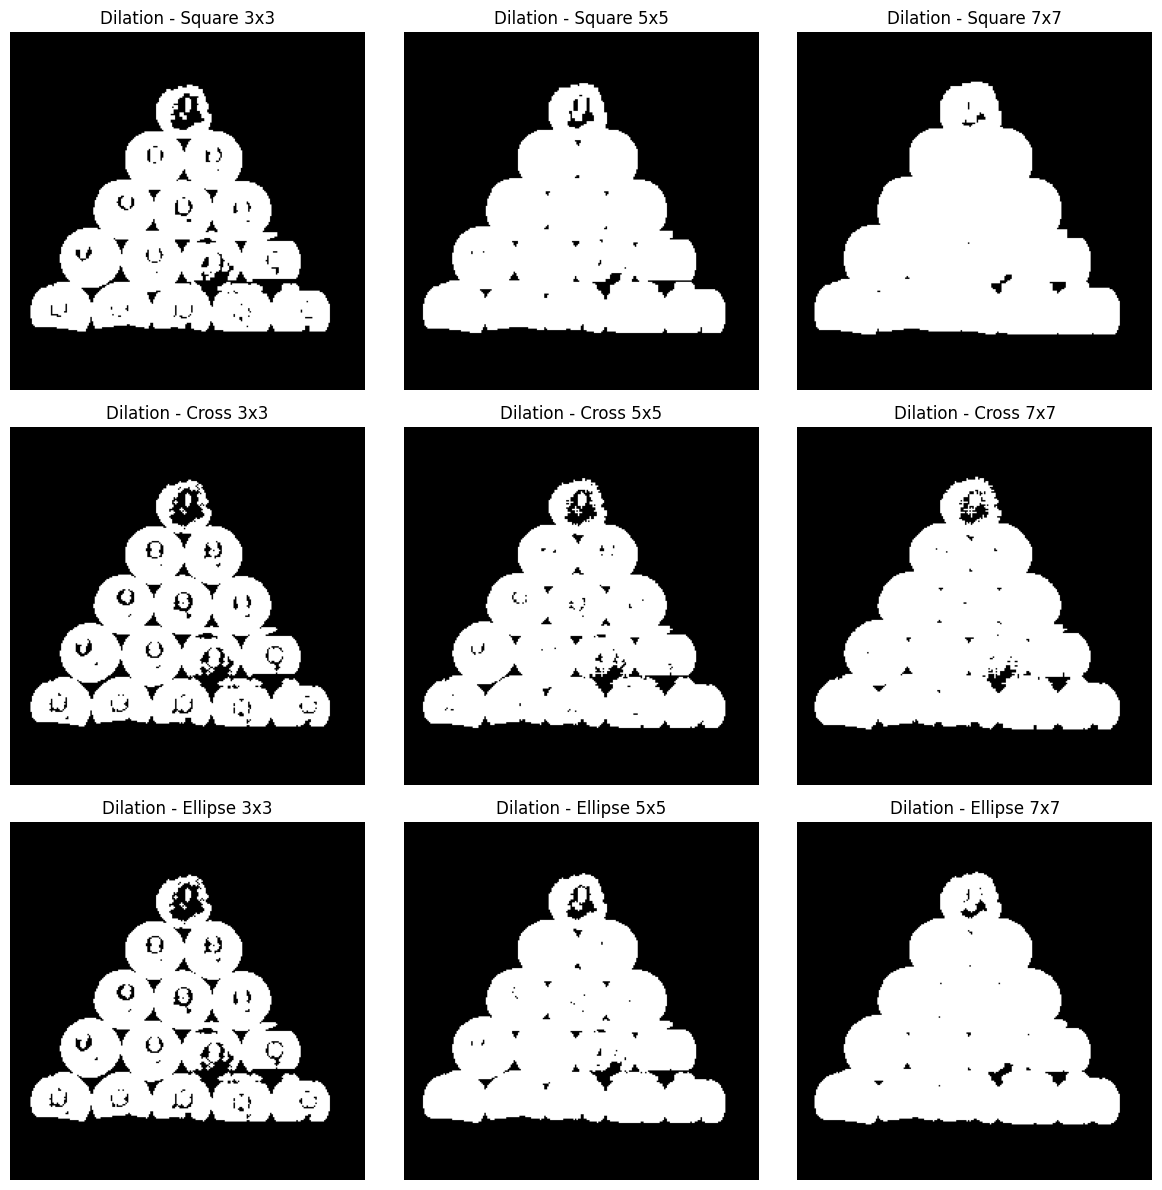

In [14]:
show_grid(cv2.dilate, 'Dilation')


## Side-by-side comparison (Original vs. 7x7 kernels)


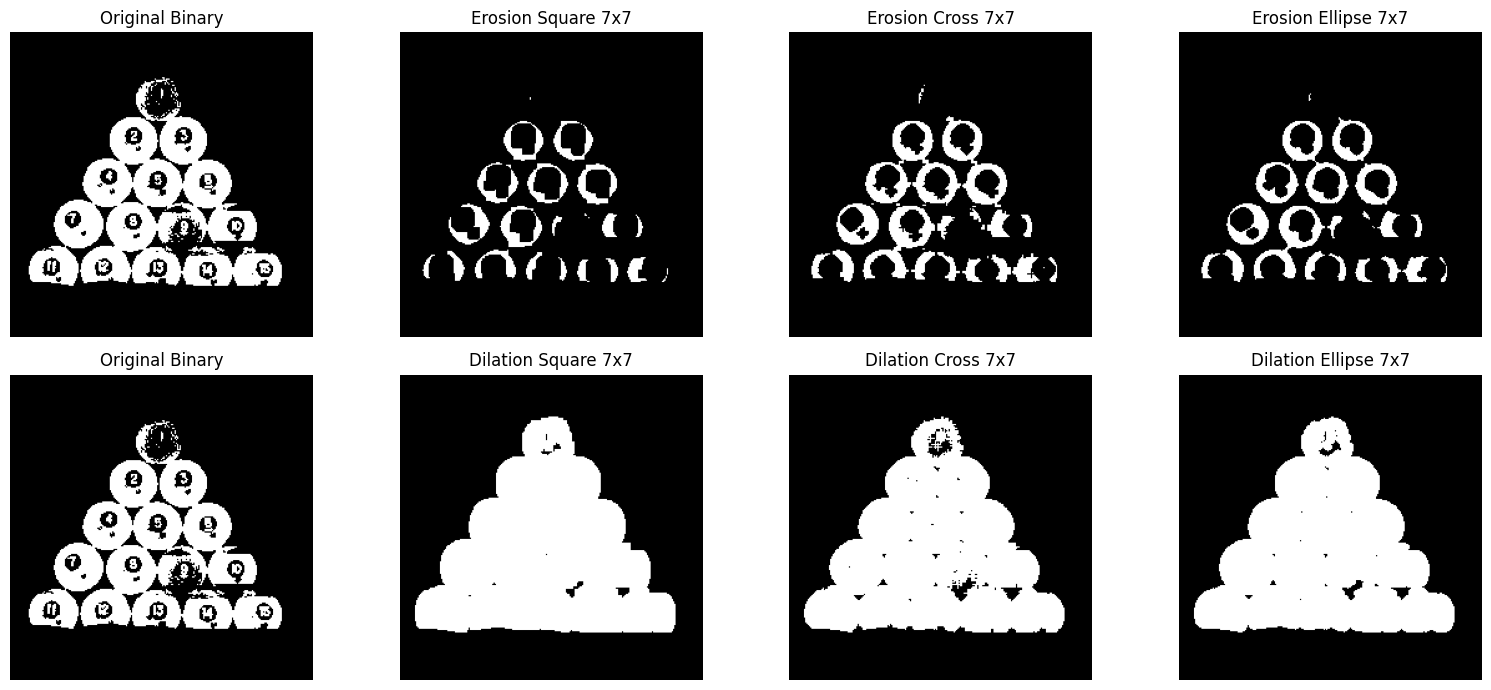

In [15]:
plt.figure(figsize=(16, 7))

plt.subplot(2, 4, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary'), plt.axis('off')
plt.subplot(2, 4, 5), plt.imshow(binary, 'gray'), plt.title('Original Binary'), plt.axis('off')

for i, (shape_name, shape) in enumerate(shapes.items()):
    kernel = cv2.getStructuringElement(shape, (7, 7))
    plt.subplot(2, 4, i + 2)
    plt.imshow(cv2.erode(binary, kernel), 'gray')
    plt.title(f'Erosion {shape_name} 7x7'); plt.axis('off')
    plt.subplot(2, 4, i + 6)
    plt.imshow(cv2.dilate(binary, kernel), 'gray')
    plt.title(f'Dilation {shape_name} 7x7'); plt.axis('off')

plt.tight_layout()
plt.show()
